# Ciencia de Datos — EDA 01
# Del análisis univariante al análisis bivariante

**Modalidad:** clase teórico-práctica  
**Dataset:** Salud y hábitos de sueño

## Objetivo de aprendizaje

Aplicar el Análisis bivariante para pasar de describir variables individualmente a explorar relaciones entre dos variables, seleccionando técnicas apropiadas e interpretando los resultados con cautela.

**Metodología:** Pregunta → variables → análisis → evidencia → interpretación → conclusión.

# 1. El caso: comprender los hábitos de sueño

Un equipo de análisis ha recibido datos sobre hábitos de sueño, actividad física, estrés y características personales. Desea comprender qué patrones aparecen en los registros y qué preguntas merecen investigación posterior.

Entre las variables hay edad, ocupación, duración y calidad del sueño, estrés, actividad física, categoría de IMC, frecuencia cardíaca, pasos diarios y trastornos del sueño.

**Pregunta orientadora:** ¿Qué podemos descubrir sin asumir de antemano que una variable causa otra?

**Alcance:** este dataset se usa con fines educativos. Una relación observada no demuestra causalidad ni permite generalizar automáticamente a toda la población. Debemos conocer cómo se obtuvieron los datos y a quiénes representan.

# 2. Preparar el entorno

In [65]:
# %pip install pandas matplotlib seaborn 

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pygwalker as pyg

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# 3. Cargar el dataset y comprobar su estructura

Ajusta la ruta a la ubicación de tu archivo CSV. Aquí suponemos que está en una carpeta `datasets` junto al notebook.

In [67]:
df = pd.read_csv("../BDD/sleep.csv")
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [68]:
df.shape

(374, 13)

In [69]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Blood Pressure           374 non-null    str    
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    str    
dtypes: float64(1), int64(7), str(5)
memory usage: 49.2 KB


### Antes de seguir

Responde en una celda Markdown:

1. ¿Cuántas filas y columnas contiene?

El dataset tiene 374 filas y 13 columnas.

2. ¿Qué variables son numéricas?

Person ID, Age, quality of Sleep, Physical Activity Level, Stress Level, Heart Rate, Daily Steps, y Sleep Duration.

3. ¿Qué variables son categóricas?

Gender, occupation, BMI Category, Blood Pressure y Sleep Disorder.

4. ¿Hay alguna variable que necesite preparación antes de analizarla?

-- En el caso de sleep duration se pueden ver 219 valores nulos, aparentemente esto representa que la persona no tiene trastorno de sueño por lo que mejor seria de reemplazar el nulo por un None.

-- Blood Pressure esta como texto y en una sola columna encontramos dos datos, por ejemplo, 125/80, para poder analizar de mejor manera se debería divir esta columna en dos diferentes.

-- BMI Category tiene ciertos textos que se prodría unificar, en este caso hay "Normal" y "Normal Weight" y podria dejarse en uno solo "Normal".

# 4. Del análisis univariante al EDA

## 4.1 Recordatorio: análisis univariante

Estudia una variable individualmente: su tendencia central, dispersión, valores frecuentes y distribución.

## 4.2 ¿Qué añade el análisis bivariante?

Estudia dos variables para explorar una posible relación, diferencia o asociación. Por ejemplo:

- duración del sueño y calidad del sueño;
- duración del sueño según grupo;
- distribución de trastornos del sueño entre categorías.

**Primero se formula la pregunta; después se elige el análisis o el gráfico.**

# 5. Bivariante: variable numérica + variable numérica

## Pregunta 1

**¿Qué patrón se observa entre la duración del sueño y la calidad del sueño?**

Escribe primero una expectativa inicial. Luego compárala con la evidencia.

In [70]:
df[["Sleep Duration", "Quality of Sleep"]].describe()

,Sleep Duration,Quality of Sleep
count,374.000000,374.000000
mean,7.132086,7.312834
std,0.795657,1.196956
min,5.800000,4.000000
25%,6.400000,6.000000
50%,7.200000,7.000000
75%,7.800000,8.000000
max,8.500000,9.000000


## 5.1 Visualizar los registros
Un diagrama de dispersión representa cada observación como un punto.

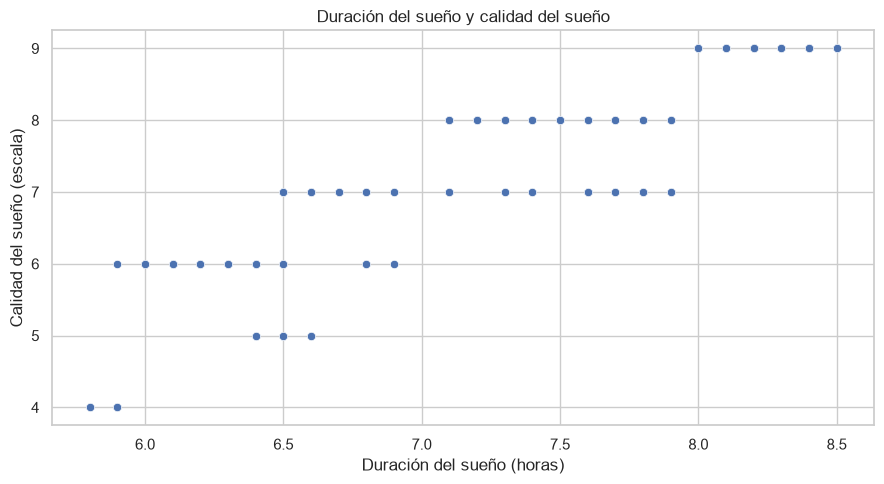

In [71]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Sleep Duration", y="Quality of Sleep")
plt.title("Duración del sueño y calidad del sueño")
plt.xlabel("Duración del sueño (horas)")
plt.ylabel("Calidad del sueño (escala)")
plt.tight_layout()
plt.show()

## 5.2 Leer el gráfico

Observa:

- **Dirección:** si ambas variables tienden a aumentar o si una disminuye cuando la otra aumenta.
- **Forma:** patrón lineal, curvo o poco evidente.
- **Concentración:** dónde se agrupan los puntos.
- **Dispersión:** cuánto varían los puntos.
- **Puntos aislados:** observaciones que podrían merecer revisión.

### Actividad de interpretación

1. ¿Qué patrón observas?
2. ¿Qué evidencia respalda tu interpretación?
3. ¿Hay excepciones o dispersión?
4. ¿Qué no puedes concluir únicamente con este gráfico?

1. Se observa que entre más horas de sueño se tenga, mejor es la puntuación de la calidad del sueño.
2. En la grafica del punto 5.1 se puede observar lo mencionado, este gráfico es lo que respalda la idea. Se puede observar que la gente que duerme entre 5 a 6 horas tiene una puntuación menor a 7, mientras que la gente que duerme 7 horas o más tiene calidad de sueño entre 7 y 9.
3. Si, existe un poco de disperción pero tampoco es tan extrema, por ejemplo hay ciertas personas que duermen menos de 7 horas y aun asi reportan calidades de entre 5 y 8.
4. No se puede concluir directramente que entre más horas duerma una persona, mejor será su calidad de sueño ya que pueden llegar a influir otros factores como el nivel de estres o trastornos de sueño.

## 5.3 Correlación: resumen numérico exploratorio

La correlación resume la dirección e intensidad de una relación **lineal** entre dos variables numéricas y suele estar entre -1 y 1:

- cercano a `1`: asociación lineal positiva;
- cercano a `-1`: asociación lineal negativa;
- cercano a `0`: poca o ninguna asociación lineal.

Un valor cercano a cero no descarta una relación no lineal. La correlación no demuestra causalidad.

In [72]:
correlacion = df["Sleep Duration"].corr(df["Quality of Sleep"])
print(f"Correlación: {correlacion:.3f}")

correlacion = df["Sleep Duration"].corr(df["Physical Activity Level"])
print(f"Correlación: {correlacion:.3f}")

correlacion = df["Sleep Duration"].corr(df["Stress Level"])
print(f"Correlación: {correlacion:.3f}")

correlacion = df["Age"].corr(df["Stress Level"])
print(f"Correlación: {correlacion:.3f}")

correlacion = df["Age"].corr(df["Quality of Sleep"])
print(f"Correlación: {correlacion}")

Correlación: 0.883
Correlación: 0.212
Correlación: -0.811
Correlación: -0.422
Correlación: 0.4737338761619918


### Actividad

Compara el valor de correlación con el diagrama de dispersión.

- ¿Ambos ofrecen una lectura compatible?
- ¿El valor numérico resume completamente el patrón?
- ¿Qué información aporta el gráfico que no aporta el coeficiente?

No interpretes la correlación sin mirar los puntos.

1. Si, el valor que se obtuvo entre estas dos variables es de 0.883, esto indica que estan bastante relacionados y que analizarlas en conjunto asegura que la información obtenida sea óptima.
2. No, falta también que resuma como se agrupan estos datos, de como se mide la calidad del sueño, o si están dispersos los datos.
3. El gráfico nos permite identificar las agrupaciones en los diferentes rangos de horas, también permite que nos demos cuenta que la calidad de sueño solo toma valores enteros y verificar que no haya valores atípicos que afecten al coeficiente.

# 6. Bivariante: variable categórica + variable numérica

## Pregunta 2

**¿Qué diferencias se observan en la duración del sueño entre los grupos de `Gender`?**

Primero calcularemos resúmenes por grupo. No basta con comparar promedios: considera también la dispersión y el tamaño de los grupos.

In [73]:
df.groupby("Gender")["Sleep Duration"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Gender,,,,,,
Female,185,7.229730,7.2,0.879434,5.8,8.5
Male,189,7.036508,7.2,0.693197,5.9,8.1


In [74]:
correlacion = df["Age"].corr(df["Sleep Duration"])
print(f"Correlación (Pearson): {correlacion:.3f}")


Correlación (Pearson): 0.345


## 6.1 Comparar distribuciones con un boxplot
El boxplot ayuda a comparar medianas, cuartiles, dispersión y posibles valores atípicos.

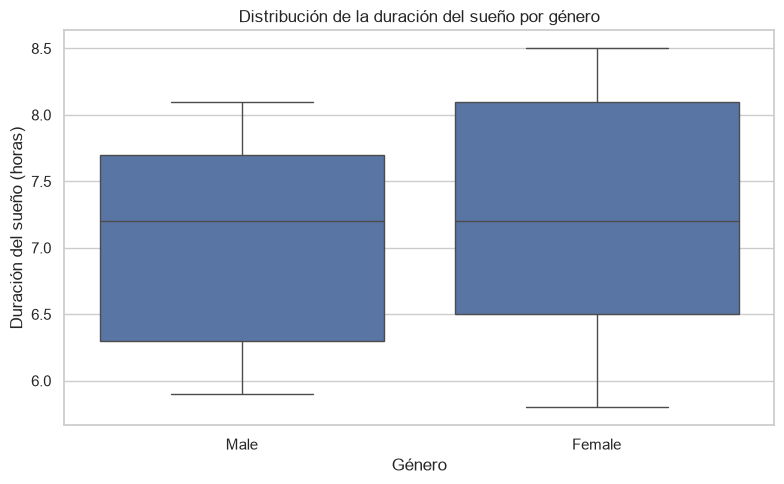

In [75]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Gender", y="Sleep Duration")
plt.title("Distribución de la duración del sueño por género")
plt.xlabel("Género")
plt.ylabel("Duración del sueño (horas)")
plt.tight_layout()
plt.show()

### Actividad de interpretación

1. Compara los resúmenes numéricos.
2. Describe una observación respaldada por el boxplot.
3. Señala una limitación de la comparación.

No afirmar que el género causa una duración específica del sueño. Describe lo que muestran estos registros.

In [76]:
# Escribe la interpretación en una celda Markdown.

1. El tamaño de la muestra esta bastante balanceada, hay 185 mujeres y 189 hombres. Por otro lado, se puede ver que la mediana de los dos grupos es exactamente la misma 7.2h y que la disperción del grupo Female tiene mayor disperción alcanzando valores máximos más altos.
2. En ninguno de los dos grupos existen valores atípicos y se puede decir que las mujeres duermen más que los hombres, esto se puede ver en la gráficai donde el borde superior de las mujeres llega más arriba.
3. No se puede afirmar que el género determina la duración del sueño, ya que no se controlan otros factores como la edad o la ocupación, variables que podrían afectar en gran medida a la interpretación.

# 7. Bivariante: variable categórica + variable categórica

## Pregunta 3

**¿Cómo se distribuyen las categorías de `Sleep Disorder` dentro de cada grupo de `Gender`?**

Una tabla de contingencia permite contar las combinaciones observadas entre categorías.

In [77]:
tabla_frecuencias = pd.crosstab(df["Gender"], df["Sleep Disorder"])
tabla_frecuencias

Sleep Disorder,Insomnia,Sleep Apnea
Gender,,
Female,36,67
Male,41,11


## 7.1 Comparar proporciones dentro de cada grupo
Las frecuencias absolutas pueden confundir si los grupos tienen tamaños distintos. Calcularemos porcentajes por fila.

In [78]:
tabla_porcentajes = pd.crosstab(
    df["Gender"],
    df["Sleep Disorder"],
    normalize="index"
) * 100

tabla_porcentajes.round(1)

Sleep Disorder,Insomnia,Sleep Apnea
Gender,,
Female,35.0,65.0
Male,78.8,21.2


### Actividad de interpretación

1. ¿Qué categoría de trastorno aparece con mayor frecuencia en cada grupo?
2. ¿Qué diferencia hay entre comparar cantidades y porcentajes?
3. ¿Qué conclusión descriptiva puedes redactar?
4. ¿Por qué la tabla no demuestra causalidad?

Si `Sleep Disorder` contiene una categoría como `None`, interprétala según el diccionario de datos; no la confundas automáticamente con un valor nulo de Pandas.

In [79]:
# Escribe tu interpretación en una celda Markdown.

1. En el grupo de las mujeres (FEMALE) predomina la apnea del sueño con una cantidad de 67 casos el cual representa el 65%. El 35% restante son casos de insomnio. Por otro lado, en los hombres (MALE) predomina el insomnio con 41 casos, el cual es el 78.8%. En el caso de los hombres solo hay 11 casos de apnea de sueño (21.2%).
2. Mirar solo la cantidad de personas no es muy bueno en este caso, porque hay el doble de mujeres que de hombres lo cual no permite obtener un buen analisis, pero al usar porcentajes se puede comparar estos dos grupos en las mismas condiciones y así poder saber que parte del total de cada grupo representa cada transtorno.
3. La apnea del sueño se presenta principalmente en el grupo de mujeres (FEMALE), mientras que el insomnio se presenta mcon más frecuencia en los hombres (MALE), si se incluyeran valores nulos/none, se puede concluir que la mayoria de hombres y mujeres no tienen ningun trastorno.
4. Porque en esta comparativa solo se muestra que pasa entre este grupo específico de datos, la diferencia de los resultados entre mujeres y hombres no necesariamente es solo por el género sino que tambien hay otros factores como la edad, peso, profesiones que pueden causar estas diferencias.

# 8. Elegir el análisis según los tipos de variables

| Tipos de variables | Pregunta típica | Herramientas exploratorias |
|---|---|---|
| Numérica + numérica | ¿Qué patrón o asociación se observa? | Diagrama de dispersión, correlación |
| Categórica + numérica | ¿Cómo cambia la distribución entre grupos? | Resumen por grupo, boxplot |
| Categórica + categórica | ¿Cómo se distribuyen las categorías conjuntamente? | Tabla de contingencia, porcentajes, barras |

Es una guía para elegir una técnica apropiada a la pregunta, no una lista rígida.

# 9. Práctica guiada: investiga tu propia pregunta

Plantea una pregunta distinta de las tres ya analizadas.

## Requisitos

1. Formular una pregunta concreta que pueda responderse con el dataset.
2. Identifica las dos variables necesarias.
3. Explica por qué esas variables ayudan a responderla.
4. Selecciona una técnica de análisis adecuada.
5. Presenta el resultado.
6. Interpreta la evidencia.
7. Señala una limitación de tu conclusión.



In [80]:
# 1. Escribe tu pregunta en una celda Markdown.
# 2. Selecciona las variables y realiza el análisis aquí.

¿Cómo varía la duración del sueño según la categoría de Índice de Masa Corporal?

Variables: BMI Category y Sleep Duration. Estas dos variables ayudan a responder esta pregunta porque permite analizar si personas que tienen soprepeso registran menos o mas horas de sueño frente a personas que tienen un peso normal. 

,count,mean,median,std,min,max
BMI Category,,,,,,
Normal,216,7.387963,7.5,0.718165,6.0,8.5
Obese,10,6.960000,7.3,0.883428,5.9,8.1
Overweight,148,6.770270,6.5,0.757768,5.8,8.2


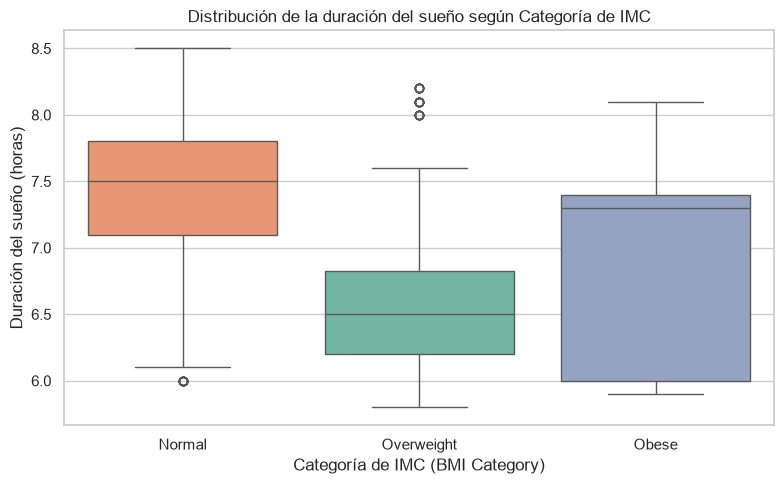

In [81]:
df_clean = df.copy()
df_clean["BMI Category"] = df_clean["BMI Category"].replace({"Normal Weight": "Normal"})
resumen_bmi = df_clean.groupby("BMI Category")["Sleep Duration"].agg(["count", "mean", "median", "std", "min", "max"])
display(resumen_bmi)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x="BMI Category",
    y="Sleep Duration",
    hue="BMI Category",
    order=["Normal", "Overweight", "Obese"],
    palette="Set2",
    legend=False
)
plt.title("Distribución de la duración del sueño según Categoría de IMC")
plt.xlabel("Categoría de IMC (BMI Category)")
plt.ylabel("Duración del sueño (horas)")
plt.tight_layout()
plt.show()

In [82]:
# Escribe tu interpretación y limitación en una celda Markdown.

-- Los datos muestran una gran diferencia entre los grupos. Se concluye que la categoría de gente con peso normal presenta una mayor duración de sueño, promediando un total de 7.39 horas y una media de 7.4 horas. Por otro lado,  la categoría de sobrepeso (Overweight) y obesos (obese) presentan una duración de sueño menor con promedios de 6.6h y 6.96h respectivamente.
-- Existe un desvalanceo entre los grupos, en el paso de la gente obesa solo hay 10 registrs y en los otros grupos hay 216 (normal) y 148 (sobrepeso) y por esta razón la estimación no es muy representativa. Por otro lado, no se puede afirmar que el IMC afecte en la duración de sueño ya que esta variable podria verse afectada por la actividad fisica o los trastornos de sueño.

# 10. Cierre: de una asociación a un hallazgo

Completa estas frases a partir de tu análisis:

- **Pregunta:** ¿qué quería investigar?
- **Evidencia:** ¿qué resultado, tabla o gráfico respalda la respuesta?
- **Interpretación:** ¿qué patrón parece mostrar la evidencia?
- **Limitación:** ¿qué no puedo afirmar?
- **Siguiente paso:** ¿qué información o análisis sería útil?


## Ideas que debes recordar

- Una asociación no demuestra causalidad.
- Un gráfico debe responder una pregunta concreta.
- Un estadístico resume información, pero puede ocultar detalles.
- Las diferencias entre grupos deben interpretarse considerando sus tamaños y distribuciones.
- Las conclusiones deben ser proporcionales a la evidencia disponible.

**El EDA consiste en formular preguntas, investigar los datos y comunicar lo que la evidencia permite sostener.**

------- RESPUESTA -------

- Pregunta: ¿Existe relación entre la categoría de IMC (BMI Category) y las horas de sueño diarias (Sleep Duration)?
- Evidencia: Tabla de estadísticas descriptivas por grupo y gráfico boxplot comparando las categorías Normal, Overweight y Obese.
- Interpretación: Los individuos con IMC Normal tienden a dormir en promedio ~0.6 horas más por noche (media 7.39 h) que aquellos con Overweight (media 6.77 h).
- Limitación: No podemos afirmar que el sobrepeso sea la razón prinicpal por la que se duerme menos horas. Por otro lado, el grupo de gente obesa (Obese) tiene un tamaño muestral muy reducido (n = 10$).
- Siguiente paso: Realizar un análisis multivariante incorporando el nivel de actividad física (Physical Activity Level), nivel de estrés (Stress Level) y presencia de apnea del sueño (Sleep Disorder).

# 11. Lista de verificación

- [X] El archivo se carga correctamente.
- [X] He revisado su estructura y las variables utilizadas.
- [X] Cada análisis responde una pregunta concreta.
- [X] He elegido técnicas acordes con los tipos de variables.
- [X] He interpretado los resultados con mis propias palabras.
- [X] No he confundido asociación con causalidad.
- [X] He indicado al menos una limitación.
- [X] Las celdas se ejecutan en orden y los resultados son visibles.

In [83]:
#NOTA: Guardar los graficos como png y luego llamarlos al notebook para visualizarlo en html y mostrar la grafica como alternativa de programar los graficos. O tambien esta la opcion de exportar código.
pyg.walk(df)

Box(children=(HTML(value='\n<div id="ifr-pyg-00065ecc749d691buPLMafQWj1lJUtk7" style="height: auto">\n    <hea…

# Parte 2: Las 3 Gráficas Bivariantes con PyGWalker

## 1. Gráfica 1: Nivel de Estrés - Duración del Sueño

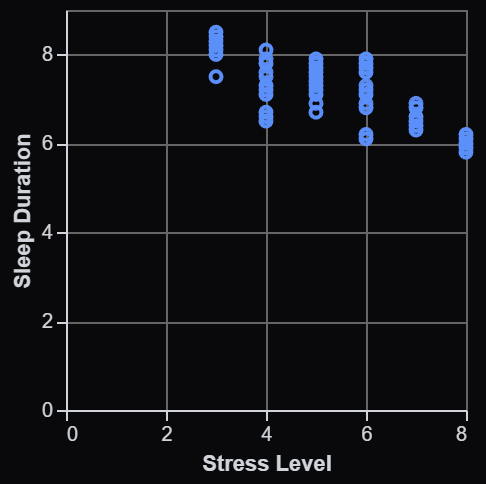

Existe una relación inversa clara donde a mayor nivel de estrés, menor es el tiempo de descanso. La gente con niveles bajos (3 y 4) promedian 8 horas o más por noche, mientras que aquellos con estrés alto (nivel 8) apenas rozan las 6 horas de sueño.

## 2. Gráfica 2: Ocupación - Calidad del Sueño

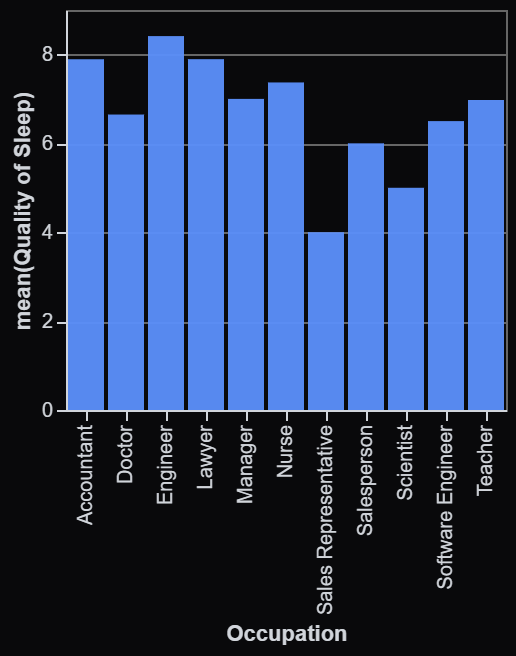

Al comparar la calidad del descanso según la profesión se evidencia una brecha marcada, personas que son ingenieros, abogados y contadores registran los puntajes más altos, mientras que puestos con mayor presión o irregularidad horaria, como científicos y representantes de ventas, obtienen los promedios más bajos del grupo.

## 3. Gráfica 3: Categoría de IMC - Trastorno del Sueño

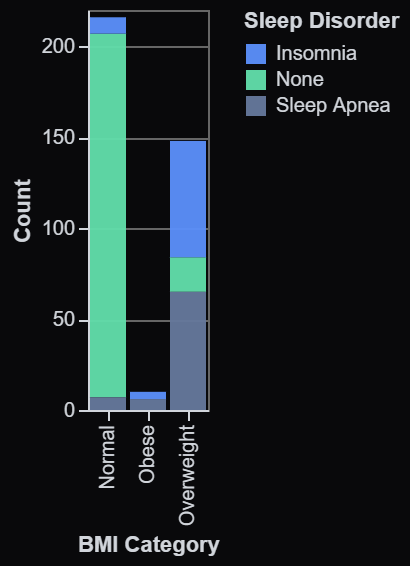

La relación entre el peso corporal y los trastornos del sueño muestra que la gran mayoría de las personas con peso normal no tiene complicaciones (None), mientras que en los grupos de sobrepeso u obesidad la tendencia cambia, presentando una gran cantidad de insomnio y apnea del sueño.

## 4. Gráfica 4: Edad - Duración del Sueño

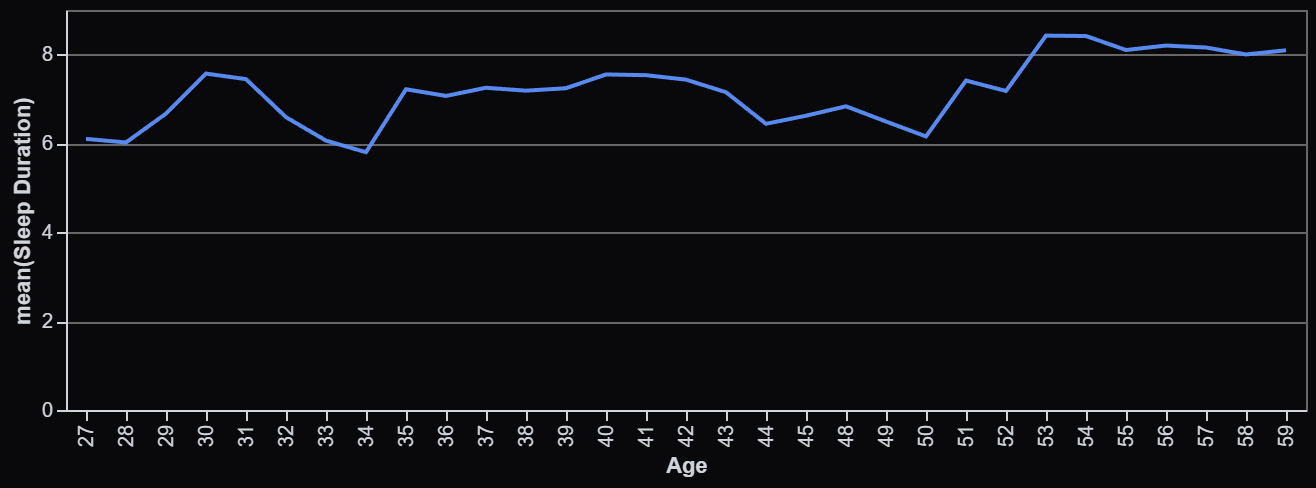

La tendencia general indica que la duración del descanso aumenta con los años, es decir, los "adultos" de entre 27 y 30 años reportan los promedios más bajos de horas de sueño dando valores de 6 a 6.5 horas y por otro lado estan los adultos mayores a 50 años que tienen los registros más altos alcanzando cerca de 8 horas de sueño.